# EXP010 — Detector YOLO + MobileSAM + clasificador ViT V4 (CPU)

**Listo para ejecutar sin entrenamiento y sin GPU.**

1. En Google Colab, elige **Entorno de ejecución → Ejecutar todas**.
2. Autoriza el acceso a tu Google Drive.
3. Si la foto no está en `/content`, el cuaderno te permite subirla.

YOLO identifica las hojas; **MobileSAM (modelo preentrenado)** intenta separar cada hoja del fondo; **tu ViT V4** clasifica cada recorte. Se guardan ambos tipos de recorte, máscaras, mosaico, CSV y resumen en una **nueva carpeta de Drive**.

**Importante:** no toca tus fotografías ni tu checkpoint V4. La segmentación no garantiza mejorar la precisión; por eso conserva las predicciones sobre recortes originales para comparar automáticamente.


In [ ]:
%pip -q install -U ultralytics transformers huggingface_hub safetensors
from google.colab import drive
drive.mount('/content/drive')


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.4.0 which is incompatible.
Mounted at /content/drive


In [ ]:
from pathlib import Path

# Si cambias la foto, modifica SOLO esta ruta.
ruta_imagen = '/content/03_2024-10-09 09;04;02_RGB.JPG'
ruta_v4 = '/content/drive/MyDrive/experimento_seminario/EXP_009/EXP009_v4_interpolacion_20261119_034557'

if not Path(ruta_imagen).is_file():
    print('Sube la fotografía de tomate desde tu PC:')
    from google.colab import files
    subidos = files.upload()
    fotos_subidas = [n for n in subidos if Path(n).suffix.lower() in {'.jpg', '.jpeg', '.png', '.webp', '.tif', '.tiff'}]
    if not fotos_subidas:
        raise FileNotFoundError('No se subio una fotografia compatible.')
    ruta_imagen = str(Path('/content') / fotos_subidas[0])

print('Foto:', ruta_imagen)
print('V4 disponible:', Path(ruta_v4).is_dir())


Sube la fotografía de tomate desde tu PC:


Saving 06_2024-10-09 09;06;52_RGB.JPG to 06_2024-10-09 09;06;52_RGB.JPG
Foto: /content/06_2024-10-09 09;06;52_RGB.JPG
V4 disponible: False


## Motor de inferencia (ya configurado)

No necesitas modificar este bloque. En la primera ejecución se descargarán los pesos de YOLO para hojas y MobileSAM.


In [ ]:
"""EXP010: YOLO detecta hojas -> MobileSAM separa cada hoja -> ViT V4 clasifica.

Listo para Google Colab SIN GPU. No entrena, no modifica los modelos ni las fotos.

Instalacion: pip install -q ultralytics transformers huggingface_hub safetensors
Uso basico: python EXP010_YOLO_MobileSAM_V4_CPU.py
Otra foto:  python EXP010_YOLO_MobileSAM_V4_CPU.py --imagen /content/otra.jpg

MobileSAM se descarga automaticamente por Ultralytics la primera vez.
El detector de hojas se descarga de GovRang/tomato-leaf-model si no se indica --detector.
"""

import argparse
import csv
import json
import os
from collections import Counter
from datetime import datetime
from pathlib import Path

import numpy as np
import torch
from PIL import Image, ImageDraw, ImageFont, ImageOps
from transformers import ViTForImageClassification, ViTImageProcessor
from ultralytics import SAM, YOLO


RUTA_FOTO = "/content/03_2024-10-09 09;04;02_RGB.JPG"
RUTA_V4 = (
    "/content/drive/MyDrive/experimento_seminario/EXP_009/"
    "EXP009_v4_interpolacion_20261119_034557"
)
NOMBRES_ES = [
    "Sana", "Moho foliar", "Tizon tardio", "Tizon temprano",
    "Mancha bacteriana", "Septoriosis", "Virus del mosaico",
]
NOMBRES_EN = [
    "Healthy", "Leaf Mold", "Late Blight", "Early Blight",
    "Bacterial Spot", "Septoria Leaf Spot", "Tomato Mosaic Virus",
]
EXTS = {".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp", ".webp"}


def argumentos():
    p = argparse.ArgumentParser(description="YOLO + MobileSAM + V4, completamente en CPU")
    p.add_argument("--imagen", default=RUTA_FOTO, help="Fotografia o carpeta de fotos")
    p.add_argument("--detector", default=None, help="Ruta al best.pt YOLO; si falta se descarga")
    p.add_argument("--v4", default=RUTA_V4, help="Carpeta del checkpoint V4")
    p.add_argument("--salida", default=None, help="Carpeta NUEVA de resultados en Drive")
    p.add_argument("--conf-yolo", type=float, default=0.50)
    p.add_argument("--imgsz-yolo", type=int, default=640)
    p.add_argument("--margen", type=float, default=0.025)
    p.add_argument("--lote-vit", type=int, default=4)
    p.add_argument("--conf-revision", type=float, default=0.70)
    return p.parse_args()


def fuente(tamano):
    for nombre in ("/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf", "C:/Windows/Fonts/arial.ttf"):
        try:
            return ImageFont.truetype(nombre, tamano)
        except OSError:
            pass
    return ImageFont.load_default()


def clasificar(imagenes, proc, vit, tam_lote):
    predicciones = []
    with torch.inference_mode():
        for inicio in range(0, len(imagenes), tam_lote):
            tramo = imagenes[inicio:inicio + tam_lote]
            entradas = proc(images=tramo, return_tensors="pt")
            probabilidades = torch.softmax(vit(pixel_values=entradas["pixel_values"]).logits, dim=-1)
            for prob in probabilidades.cpu().numpy():
                top2 = np.argsort(prob)[-2:][::-1]
                a, b = int(top2[0]), int(top2[1])
                predicciones.append({
                    "clase": NOMBRES_ES[a], "clase_en": NOMBRES_EN[a],
                    "confianza": round(float(prob[a]), 6),
                    "segunda": NOMBRES_ES[b],
                    "margen_top2": round(float(prob[a] - prob[b]), 6),
                })
    return predicciones


def localizar_hojas(detector, foto, conf, tamano, margen):
    ancho, alto = foto.size
    r = detector.predict(
        source=foto, device="cpu", conf=conf, imgsz=tamano,
        iou=0.5, max_det=100, agnostic_nms=True, verbose=False, save=False,
    )[0]
    hojas = []
    if r.boxes is None:
        return hojas
    for coords, puntuacion, clase in zip(
        r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy(),
        r.boxes.cls.cpu().numpy().astype(int),
    ):
        x1, y1, x2, y2 = [float(z) for z in coords]
        if x2 - x1 < 28 or y2 - y1 < 28:
            continue
        dx, dy = (x2 - x1) * margen, (y2 - y1) * margen
        recorte = (
            max(0, int(x1 - dx)), max(0, int(y1 - dy)),
            min(ancho, int(np.ceil(x2 + dx))), min(alto, int(np.ceil(y2 + dy))),
        )
        if recorte[2] > recorte[0] and recorte[3] > recorte[1]:
            hojas.append({
                "bbox_sam": [round(x1), round(y1), round(x2), round(y2)],
                "bbox_crop": recorte,
                "conf_yolo": round(float(puntuacion), 6),
                "clase_yolo": int(clase),
            })
    return sorted(hojas, key=lambda h: (h["bbox_crop"][1], h["bbox_crop"][0]))


def obtener_mascaras(sam, foto, hojas):
    """Una pasada del encoder para TODAS las cajas; retorna máscaras binarias alineadas."""
    caja_prompts = [h["bbox_sam"] for h in hojas]
    try:
        salida = sam.predict(
            source=foto, bboxes=caja_prompts, device="cpu", verbose=False, save=False,
        )[0]
        if salida.masks is None:
            raise RuntimeError("MobileSAM no devolvio mascaras")
        mascaras = salida.masks.data
        mascaras = mascaras.cpu().numpy() if hasattr(mascaras, "cpu") else np.asarray(mascaras)
        if len(mascaras) != len(hojas):
            raise RuntimeError(f"MobileSAM devolvio {len(mascaras)} mascaras para {len(hojas)} hojas")
        alto, ancho = foto.height, foto.width
        salida_mascaras = []
        for matriz in mascaras:
            img = Image.fromarray((matriz > 0).astype("uint8") * 255, "L")
            if img.size != (ancho, alto):
                img = img.resize((ancho, alto), Image.Resampling.NEAREST)
            salida_mascaras.append(img)
        return salida_mascaras, "ok"
    except Exception as exc:
        print(f"  AVISO MobileSAM: {type(exc).__name__}: {exc}")
        print("  Se conservan los recortes YOLO como respaldo; no se inventan mascaras.")
        return [None] * len(hojas), f"error: {exc}"


def recorte_segmentado(original, mascara_completa, bbox):
    recorte = original.crop(bbox)
    if mascara_completa is None:
        return recorte.copy(), None, "sin_mascara"
    m = mascara_completa.crop(bbox)
    pixeles = np.asarray(m) > 0
    cobertura = float(pixeles.mean())
    if cobertura < .12:
        return recorte.copy(), m, "mascara_descartada_por_cobertura"
    # Color neutro: el fondo no se confunde con zonas verdes de otras hojas.
    fondo = Image.new("RGB", recorte.size, (125, 125, 125))
    segmentada = Image.composite(recorte, fondo, m)
    return segmentada, m, "segmentada"


def mosaico(filas, pares, destino):
    """Vista de pares para inspeccion documental; no cambia predicciones."""
    if not filas:
        return
    tam_w, tam_h, encabezado, margen = 280, 190, 42, 12
    lienzo = Image.new("RGB", (2 * tam_w + 3 * margen, len(filas) * (tam_h + encabezado + margen) + margen), "white")
    d = ImageDraw.Draw(lienzo)
    f = fuente(16)
    for i, (fila, (normal, segmentado)) in enumerate(zip(filas, pares)):
        y = margen + i * (tam_h + encabezado + margen)
        titulo = (f"Hoja {fila['hoja']:02d} | Rect.: {fila['clase_rectangulo']} "
                  f"{fila['conf_rectangulo']:.0%} | Seg.: {fila['clase_segmentada']} "
                  f"{fila['conf_segmentada']:.0%}")
        d.text((margen, y), titulo, fill="black", font=f)
        for k, imagen in enumerate((normal, segmentado)):
            mini = ImageOps.contain(imagen, (tam_w, tam_h))
            x = margen + k * (tam_w + margen)
            lienzo.paste(mini, (x + (tam_w - mini.width) // 2, y + encabezado))
    lienzo.save(destino / "mosaico_comparativo.jpg", quality=92)


def procesar_imagen(ruta, ordinal, destino, detector, sam, proc, vit, args):
    with Image.open(ruta) as f:
        foto = ImageOps.exif_transpose(f).convert("RGB")
    hojas = localizar_hojas(detector, foto, args.conf_yolo, args.imgsz_yolo, args.margen)
    carpeta = destino / f"foto_{ordinal:03d}_{ruta.stem[:35]}"
    carpeta.mkdir(parents=True, exist_ok=False)
    if not hojas:
        print(f"  {ruta.name}: ninguna hoja detectada por YOLO")
        return []
    mascaras, estado_sam = obtener_mascaras(sam, foto, hojas)
    rectangulares, segmentadas, metadatos = [], [], []
    for n, (h, mascara) in enumerate(zip(hojas, mascaras), 1):
        r = foto.crop(h["bbox_crop"])
        s, m, estado = recorte_segmentado(foto, mascara, h["bbox_crop"])
        r.save(carpeta / f"hoja_{n:03d}_rectangulo.jpg", quality=95)
        s.save(carpeta / f"hoja_{n:03d}_segmentada.jpg", quality=95)
        if m is not None:
            m.save(carpeta / f"hoja_{n:03d}_mascara.png")
        rectangulares.append(r)
        segmentadas.append(s)
        metadatos.append(estado)

    pred_r = clasificar(rectangulares, proc, vit, args.lote_vit)
    pred_s = clasificar(segmentadas, proc, vit, args.lote_vit)
    marcada = foto.copy()
    d = ImageDraw.Draw(marcada)
    f = fuente(max(13, min(24, foto.width // 65)))
    filas = []
    for n, (h, p_r, p_s, estado) in enumerate(zip(hojas, pred_r, pred_s, metadatos), 1):
        insegura = (p_s["confianza"] < args.conf_revision or p_s["margen_top2"] < .15)
        color = (232, 141, 30) if insegura else (26, 148, 89)
        x1, y1, x2, y2 = h["bbox_crop"]
        d.rectangle((x1, y1, x2, y2), outline=color, width=4)
        texto = f"H{n:02d} {p_s['clase']} {p_s['confianza']:.0%}"
        lim = d.textbbox((0, 0), texto, font=f)
        tw, th = lim[2] - lim[0] + 12, lim[3] - lim[1] + 10
        tx, ty = max(0, min(x1, foto.width - tw)), max(0, y1 - th)
        d.rectangle((tx, ty, tx + tw, ty + th), fill=color)
        d.text((tx + 6, ty + 4), texto, fill="white", font=f)
        filas.append({
            "foto": str(ruta), "hoja": n,
            "x1": x1, "y1": y1, "x2": x2, "y2": y2,
            "confianza_yolo": h["conf_yolo"],
            "estado_mascara": estado,
            "clase_rectangulo": p_r["clase"], "conf_rectangulo": p_r["confianza"],
            "clase_segmentada": p_s["clase"], "conf_segmentada": p_s["confianza"],
            "segunda_clase": p_s["segunda"], "margen_top2": p_s["margen_top2"],
            "cambio_clase": p_r["clase"] != p_s["clase"],
            "requiere_revision": insegura,
        })

    marcada.save(carpeta / "foto_clasificada.jpg", quality=94)
    mosaico(filas, list(zip(rectangulares, segmentadas)), carpeta)
    with (carpeta / "resultados.csv").open("w", newline="", encoding="utf-8-sig") as f_csv:
        escritor = csv.DictWriter(f_csv, fieldnames=list(filas[0]))
        escritor.writeheader()
        escritor.writerows(filas)
    print(f"  {ruta.name}: {len(filas)} hojas | MobileSAM: {estado_sam} | "
          f"{sum(f['requiere_revision'] for f in filas)} por revisar")
    return filas


def main():
    args = argumentos()
    torch.set_num_threads(min(4, os.cpu_count() or 2))
    entrada = Path(args.imagen).expanduser()
    ruta_v4 = Path(args.v4).expanduser()
    if not entrada.exists():
        raise FileNotFoundError(f"No existe la foto: {entrada}. Cambia --imagen o subela a Colab.")
    for requerido in ("config.json", "model.safetensors", "preprocessor_config.json"):
        if not (ruta_v4 / requerido).is_file():
            raise FileNotFoundError(f"Falta el archivo V4: {ruta_v4 / requerido}. Monta Drive.")
    fotos = ([entrada] if entrada.is_file() else
             sorted(p for p in entrada.iterdir() if p.is_file() and p.suffix.lower() in EXTS))
    if not fotos or any(f.suffix.lower() not in EXTS for f in fotos):
        raise ValueError("No hay fotos validas. Usa JPG, PNG, TIFF o WEBP.")
    if args.detector:
        ruta_yolo = Path(args.detector).expanduser()
        if not ruta_yolo.is_file():
            raise FileNotFoundError(f"No existe detector YOLO: {ruta_yolo}")
    else:
        from huggingface_hub import hf_hub_download
        ruta_yolo = Path(hf_hub_download(repo_id="GovRang/tomato-leaf-model", filename="best.pt"))

    destino = (Path(args.salida).expanduser() if args.salida else
               ruta_v4.parent / "inferencias_YOLO_MobileSAM_V4" /
               ("inferencia_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f")))
    origen_resuelto, destino_resuelto = entrada.resolve(), destino.resolve()
    v4_resuelto = ruta_v4.resolve()
    if (destino_resuelto == origen_resuelto or destino_resuelto == v4_resuelto or
            origen_resuelto in destino_resuelto.parents or
            v4_resuelto in destino_resuelto.parents or
            (entrada.is_file() and destino_resuelto == origen_resuelto.parent)):
        raise ValueError("La salida debe estar fuera del origen y del checkpoint V4.")
    destino.mkdir(parents=True, exist_ok=False)

    print("EXP010 | YOLO + MobileSAM preentrenado + ViT V4 | CPU")
    print("Imagenes:", len(fotos), "| V4:", ruta_v4)
    print("Cargando detector YOLO ...")
    detector = YOLO(str(ruta_yolo))
    if len(detector.names) != 1 or "leaf" not in str(list(detector.names.values())).lower():
        print("AVISO: confirma que YOLO detecta HOJAS. Clases actuales:", detector.names)
    print("Cargando MobileSAM (primera ejecucion descarga mobile_sam.pt) ...")
    sam = SAM("mobile_sam.pt")
    print("Cargando clasificador V4 ...")
    proc = ViTImageProcessor.from_pretrained(str(ruta_v4))
    vit = ViTForImageClassification.from_pretrained(str(ruta_v4)).eval().to("cpu")
    if vit.config.num_labels != 7:
        raise RuntimeError("El checkpoint V4 esperado tiene exactamente 7 clases.")

    todas, errores = [], []
    for idx, foto in enumerate(fotos, 1):
        try:
            todas.extend(procesar_imagen(foto, idx, destino, detector, sam, proc, vit, args))
        except Exception as exc:
            errores.append({"foto": str(foto), "error": str(exc)})
            print(f"  ERROR {foto.name}: {type(exc).__name__}: {exc}")
    campos = [
        "foto", "hoja", "x1", "y1", "x2", "y2", "confianza_yolo",
        "estado_mascara", "clase_rectangulo", "conf_rectangulo",
        "clase_segmentada", "conf_segmentada", "segunda_clase", "margen_top2",
        "cambio_clase", "requiere_revision",
    ]
    with (destino / "TODAS_las_hojas.csv").open("w", newline="", encoding="utf-8-sig") as f_csv:
        escritor = csv.DictWriter(f_csv, fieldnames=campos)
        escritor.writeheader()
        escritor.writerows(todas)
    resumen = {
        "total_fotos": len(fotos), "total_hojas": len(todas),
        "predicciones_hojas_segmentadas": dict(Counter(f["clase_segmentada"] for f in todas)),
        "cambios_entre_recorte_y_segmentacion": sum(f["cambio_clase"] for f in todas),
        "requieren_revision": sum(f["requiere_revision"] for f in todas),
        "con_mascara": sum(f["estado_mascara"] == "segmentada" for f in todas),
        "errores": errores, "checkpoint_v4": str(ruta_v4),
        "nota": "No demuestra mejora de exactitud. Las confianzas de YOLO corresponden a "
                "deteccion de hojas, no a enfermedad. Las del ViT no estan calibradas. "
                "Las predicciones requieren validacion con etiquetas reales.",
    }
    (destino / "resumen.json").write_text(json.dumps(resumen, indent=2, ensure_ascii=False), encoding="utf-8")
    print("\nRESULTADO COMPLETADO")
    print("Hojas:", len(todas), "| Con mascara:", resumen["con_mascara"])
    print("Clases V4 en segmentadas:", resumen["predicciones_hojas_segmentadas"])
    print("Cambios frente al recorte normal:", resumen["cambios_entre_recorte_y_segmentacion"])
    print("Resultados guardados:", destino)
    print("Las fotos originales y los modelos no fueron modificados.")




Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [13]:
from pathlib import Path

base = Path(
    "/content/drive/MyDrive/"
    "experimento_seminario_2026/"
    "experimento_seminario"
)

print("¿Existe la carpeta?", base.is_dir())

modelos = []

if base.is_dir():
    for archivo in base.rglob("config.json"):
        carpeta = archivo.parent

        if (
            "v4" in str(carpeta).lower()
            and (carpeta / "model.safetensors").is_file()
            and (carpeta / "preprocessor_config.json").is_file()
        ):
            modelos.append(carpeta)

if len(modelos) == 1:
    ruta_v4 = str(modelos[0])

    print("\n✅ V4 ENCONTRADO:")
    print(ruta_v4)

elif len(modelos) > 1:
    print("\nSe encontraron varios V4:")
    for modelo in modelos:
        print(modelo)

else:
    print("\nNo se encontró V4 en esta ubicación.")

¿Existe la carpeta? True

✅ V4 ENCONTRADO:
/content/drive/MyDrive/experimento_seminario_2026/experimento_seminario/EXP_009/EXP009_v4_interpolacion_20261119_034557


In [10]:
from pathlib import Path
import os

raiz = Path("/content/drive/MyDrive")

print("¿MyDrive está disponible?", raiz.is_dir())

if raiz.is_dir():
    print("\nCARPETAS PRINCIPALES:")
    for carpeta in sorted(raiz.iterdir()):
        if carpeta.is_dir():
            print("📁", carpeta.name)

    print("\nBUSCANDO EL MODELO V4...")

    encontrados = []

    for directorio, subcarpetas, archivos in os.walk(raiz):
        ruta = Path(directorio)

        # Limitar la búsqueda a cinco niveles de carpetas.
        profundidad = len(ruta.relative_to(raiz).parts)
        if profundidad >= 5:
            subcarpetas[:] = []

        if "EXP009_v4" in ruta.name:
            print("\nPosible modelo:", ruta)

            if all(
                (ruta / nombre).is_file()
                for nombre in [
                    "config.json",
                    "model.safetensors",
                    "preprocessor_config.json"
                ]
            ):
                encontrados.append(ruta)

    if len(encontrados) == 1:
        ruta_v4 = str(encontrados[0])
        print("\n✅ MODELO V4 RECUPERADO:")
        print(ruta_v4)

    elif len(encontrados) > 1:
        print("\nSe encontraron varios modelos:", encontrados)

    else:
        print("\nNo se encontró V4 completo en las carpetas examinadas.")

¿MyDrive está disponible? True

CARPETAS PRINCIPALES:
📁 AgroTech_EXP008_Entrenamiento_sin_Drive_Paquete
📁 Colab Notebooks
📁 INGLES (ASW)
📁 JUEGOS 2
📁 ViT_tomate_experimentos
📁 experimento_seminario_2026

BUSCANDO EL MODELO V4...

Posible modelo: /content/drive/MyDrive/experimento_seminario_2026/experimento_seminario/EXP_009/EXP009_v4_interpolacion_20261119_034557

✅ MODELO V4 RECUPERADO:
/content/drive/MyDrive/experimento_seminario_2026/experimento_seminario/EXP_009/EXP009_v4_interpolacion_20261119_034557


In [14]:
import sys
sys.argv = ['EXP010', '--imagen', ruta_imagen, '--v4', ruta_v4, '--conf-yolo', '0.50']
main()


best.pt: reconstructing file:   0%|          |  0.00B / 6.25MB            

best.pt: downloading bytes:           |  0.00B            

EXP010 | YOLO + MobileSAM preentrenado + ViT V4 | CPU
Imagenes: 1 | V4: /content/drive/MyDrive/experimento_seminario_2026/experimento_seminario/EXP_009/EXP009_v4_interpolacion_20261119_034557
Cargando detector YOLO ...
Cargando MobileSAM (primera ejecucion descarga mobile_sam.pt) ...
Cargando clasificador V4 ...


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

/tmp/ipykernel_1037/2876812551.py:133: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray((matriz > 0).astype("uint8") * 255, "L")


  06_2024-10-09 09;06;52_RGB.JPG: 2 hojas | MobileSAM: ok | 2 por revisar

RESULTADO COMPLETADO
Hojas: 2 | Con mascara: 2
Clases V4 en segmentadas: {'Moho foliar': 2}
Cambios frente al recorte normal: 0
Resultados guardados: /content/drive/MyDrive/experimento_seminario_2026/experimento_seminario/EXP_009/inferencias_YOLO_MobileSAM_V4/inferencia_20261119_190957_485382
Las fotos originales y los modelos no fueron modificados.


CARPETA DE RESULTADOS: /content/drive/MyDrive/experimento_seminario_2026/experimento_seminario/EXP_009/inferencias_YOLO_MobileSAM_V4/inferencia_20261119_190957_485382
CSV general: /content/drive/MyDrive/experimento_seminario_2026/experimento_seminario/EXP_009/inferencias_YOLO_MobileSAM_V4/inferencia_20261119_190957_485382/TODAS_las_hojas.csv
Mosaico comparativo:


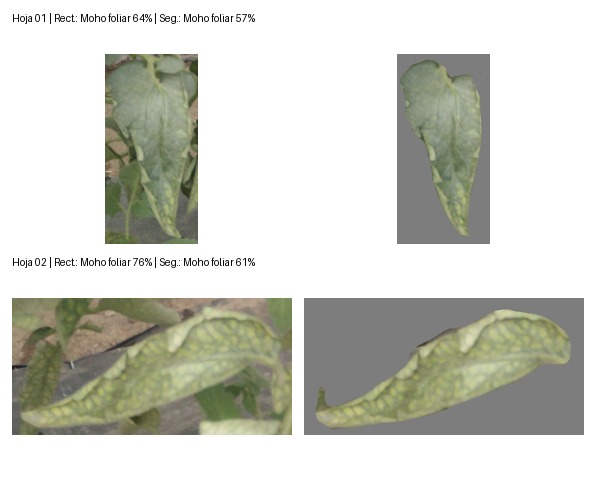

In [15]:
from IPython.display import display, Image as MostrarImagen

carpeta_base = Path(ruta_v4).parent / 'inferencias_YOLO_MobileSAM_V4'
ejecuciones = sorted((p for p in carpeta_base.glob('inferencia_*') if p.is_dir()), reverse=True)
if ejecuciones:
    ultima = ejecuciones[0]
    print('CARPETA DE RESULTADOS:', ultima)
    print('CSV general:', ultima / 'TODAS_las_hojas.csv')
    print('Mosaico comparativo:')
    for muestra in list(ultima.glob('*/mosaico_comparativo.jpg'))[:2]:
        display(MostrarImagen(filename=str(muestra)))
